# Logistic Regression and SVM

In this assignment you will:
- learn how to train logistic regression
- learn how to train an SVM
- try tuning hyperparameters

As before, we will work with the `sklearn` library and use `seaborn` for visualization.
Let's import the required libraries and set up the plot styles.
<font color='OrangeRed'>**Note!**</font> You may need a recent version of <font color='CornflowerBlue'>**sklearn>=1.3**</font>

In [1]:
import sklearn
import pandas as pd
import numpy as np


import seaborn as sns
import matplotlib.pyplot as plt

import matplotlib_inline

import time
from tqdm.auto import tqdm

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import LinearSVC, SVC
from sklearn.datasets import make_classification

sns.set(style="ticks", context="talk")
sns.set_style("darkgrid")
matplotlib_inline.backend_inline.set_matplotlib_formats('pdf', 'svg')

pd.set_option('display.max_columns', None)

import warnings
warnings.filterwarnings("ignore")

## Logistic regression
We will use sklearn's built-in `make_classification` function to create a dataset suitable for classification. Do all of the following steps and run the classification on it.

In [2]:
X, y = make_classification(n_samples=1000, n_features=2, n_redundant=0, n_repeated=0, n_classes=2, n_clusters_per_class=1, random_state=14)

df = pd.DataFrame(np.hstack((X, y[:, None])), columns=["f1", "f2", "target"]) # c этим датасетом вам и нужно работать

* **[1 point]** Split the data into training and test sets and normalize it.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

* **[1 point]** Train a logistic regression ([LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#logisticregression)). Keep the default model parameters.

In [4]:
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

* **[1 point]** Unlike the support vector machine, logistic regression does not try to build a separating hyperplane with the maximum margin. Instead, at every point of the feature space it approximates the probability of the positive class $p(y = +1 | x)$. Plot this distribution on the chart below (keep the objects themselves on the chart as well).

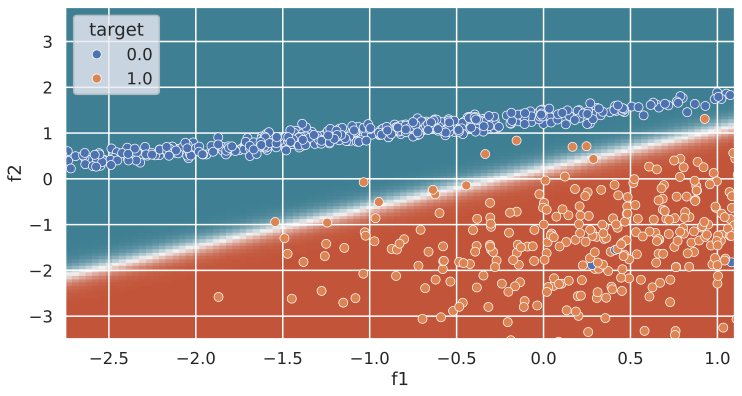

In [5]:
# Пропишем некоторые настройки графика
fix, ax = plt.subplots(figsize=(12, 6))
ax.set_xlim(-2.75, 1.1)
ax.set_ylim(-3.5, 3.75)

palette = sns.color_palette("tab10")

xx = np.linspace(*ax.get_xlim(), 100)
yy = np.linspace(*ax.get_ylim(), 100)
x_grid, y_grid = np.meshgrid(xx, yy)

grid = np.c_[x_grid.ravel(), y_grid.ravel()]

# Вычислите предсказание модели в каждой точке сетки (grid)
# Для этого вспомните, какой метод класса LogisticRegression возвращает вероятности (было на семинаре)
grid_proba = lr.predict_proba(grid)[:, 1]
grid_proba = grid_proba.reshape(x_grid.shape)

image = plt.imshow(grid_proba, interpolation='nearest', extent=(*ax.get_xlim(), *ax.get_ylim()),
                    aspect='auto', origin='lower', cmap=sns.diverging_palette(220, 20, sep=10, as_cmap=True))

sns.scatterplot(df, x="f1", y="f2", hue="target")
plt.show()

* **[1 point]** Compare `accuracy`, `precision`, `recall` and the `F1 score`

In [6]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

# Напишите функцию для сравнения accuracy, precision, recall, F1-меры
def metrics(model_name, y_true, y_pred):
    print(f"Метрики для {model_name}")
    print(f"Accuracy: {accuracy_score(y_true, y_pred)}")
    print(f"Precision: {precision_score(y_true, y_pred)}")
    print(f"Recall: {recall_score(y_true, y_pred)}")
    print(f"F1: {f1_score(y_true, y_pred)}")



# Воспользуйтесь функцией и сравните метрики
metrics("Log Reg", y_test, lr_pred)

Метрики для Log Reg
Accuracy: 0.98
Precision: 0.9897959183673469
Recall: 0.97
F1: 0.9797979797979798



* **[0.5 points]** How is the region where $p(y = +1 | x) = 0.5$ shown on the chart? Which objects fall into it?

**Answer:**
The region is shown as the white line.
The objects that fall into it can be seen in the picture.

![image.png](attachment:image.png)

##  SVM
Now let's try an SVM and repeat roughly the same steps.

* **[0.5 points]** Train an [SVC(kernel='linear')](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html#sklearn.svm.SVC) model. This is an SVM with a linear kernel, similar to LinearSVC, but it gives access to the support vectors, which we need for the visualization. Keep the other parameters at their defaults.

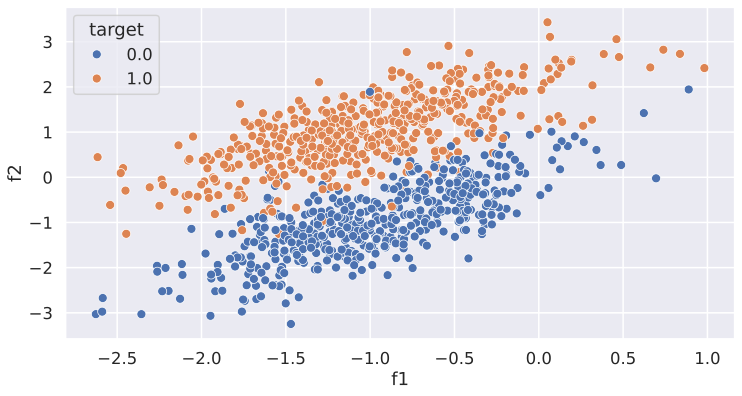

In [7]:
# Опять создадим датасет для классификации
X, y = make_classification(n_samples=1000, n_features=2, n_redundant=0, n_repeated=0, n_classes=2, n_clusters_per_class=1, random_state=12)

df = pd.DataFrame(np.hstack((X, y[:, None])), columns=["f1", "f2", "target"])

fix, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(df, x="f1", y="f2", hue="target")
plt.show()

* **[1 point]** On the chart below (or on a similar chart of your own) highlight the objects that were selected as support vectors. The support vectors are available through the `support_vectors_` or `support_` attributes (see the SVC documentation linked above).
 - Support vectors are all points with $\xi_i > 0$
 - If $\xi_i = 0$, the point is not a support vector: it lies outside the margin and does not affect the separation

In [8]:
# Разделите данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Нормализуйте данные
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Обучите модель
model_svm = SVC(kernel='linear', random_state=42)
model_svm.fit(X_train, y_train)

svm_pred = model_svm.predict(X_test)

# Воспользуйтесь написанной ваши выше функцией metrics и сравните метрики
metrics("SVM", y_test, svm_pred)

Метрики для SVM
Accuracy: 0.96
Precision: 0.98
Recall: 0.9423076923076923
F1: 0.9607843137254902


In [9]:
# Получите опорные векторы и выведите их
support_vectors = model_svm.support_
print(support_vectors)

# Получите коэффициенты весов (воспользуйтесь методом класса SVC)
coef = model_svm.coef_
print(coef)

[  0   4  17  24  34  75  92  95  96 107 114 115 126 127 130 135 136 144
 152 160 173 193 203 205 207 215 227 233 237 243 253 269 281 290 294 309
 323 329 330 337 339 353 358 359 368 373 380 384 385 391 392 395 403 406
 408 410 413 420 421 423 426 435 467 468 474 484 495 496 497 502 510 515
 517 533 534 541 542 547 551 556 558 560 574 576 593 604 605 624 627 632
 636 637 656 666 678 681 692 719 720 722 723 724 726 728 735 736 739 753
 757 764 774 784 793 797 798  16  25  38  40  48  65  67  78  85  86 103
 108 139 142 147 151 154 158 163 184 189 190 196 199 206 217 220 221 228
 229 236 240 250 251 263 272 273 277 282 284 291 297 305 307 310 311 343
 369 382 390 402 407 409 412 418 424 427 432 436 438 445 446 453 458 459
 461 471 472 480 481 493 499 507 518 528 538 543 546 552 553 557 568 579
 581 585 588 614 617 623 625 635 642 651 658 660 661 664 670 671 674 679
 680 690 693 704 706 707 712 743 744 745 761 777 780 781 789]
[[-4.58026707  9.14516955]]


* **[0.5 points]** What can you say about the linear separability of the data based on the support vectors (what do you see in the picture)?

**Your answer:**

![image-2.png](attachment:image-2.png)
Clearly, the data is not linearly separable.

## Working with a dataset
We will look at the [career change dataset](https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists).
The target is whether a person is ready to change jobs or not.

**Problem statement:**
Imagine you work at an HR company that is actively looking for new employees. You need to decide which candidates are worth calling and which are not. You do not want to waste time on candidates who are not ready to join your company, but you also do not want to miss valuable new hires. Calling one person costs the company 500 tugriks. If the person you called really was looking for a new job, you earn 200 tugriks. Your task is to train a logistic regression and choose the threshold that maximizes your profit.

In [ ]:
df = pd.read_csv('aug_train.csv')

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc, precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score

# Проверка пропущенных значений
print(df.isnull().sum())

# Заполните пропущенные значения медианой (или модой для категориальных признаков)


# Выделяем целевую переменную
y = df['target']

# Выбираем признаки (убираем id, target и ненужные столбцы)
X = df.drop(columns=['enrollee_id', 'target'])

# Разделяем на тренировочную и тестовую выборку
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)



enrollee_id                  0
city                         0
city_development_index       0
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
last_new_job               423
training_hours               0
target                       0
dtype: int64


In [ ]:
# Выделите категориальные и числовые призанки в два массива
num_features = ...
cat_features = ...

# дополните недостающие поля в предобработке и пайплане
preprocessor = ColumnTransformer([
    ...
])

model = Pipeline([
    ...,
    ('classifier', LogisticRegression())
])

# Обучаем модель
model.fit(X_train, y_train)

# Сделайте предсказания для тестовой выборки
y_probs = ...

TypeError: cannot unpack non-iterable ellipsis object

In [ ]:
# Вычисляем ROC-кривую и AUC
fpr, tpr = roc_curve(y_test, y_probs)
roc_auc = ... # Посчитайте AUC

# Визуализация ROC-кривой
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0,1], [0,1], 'k--')  # Диагональ случайного классификатора
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая')
plt.legend(loc="lower right")
plt.show()


In [ ]:
thresholds = np.linspace(0.1, 0.9, 9)
metrics = []

# Переберите все возможные пороги и посчитайте метрики на них
for threshold in thresholds:
    y_pred = ...
    acc = ...
    prec = ...
    rec = ...
    f1 = ...
    metrics.append([threshold, acc, prec, rec, f1])

# Создайте DataFrame с метриками
metrics_df = pd.DataFrame(...)

# Визуализируете метрики
plt.figure(figsize=(10,6))
# YOUR CODE HERE
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall и F1-score в зависимости от порога")
plt.legend()
plt.show()


In [ ]:
metrics_df

**Explain in detail which threshold should be chosen and why. Which metrics did you look at? Why those? If needed, add extra code and/or calculations below.**

**Your answer:**